# Customer complaints: data analysis

In this notebook I go through the complaints data in four steps: gathering, assessing, cleaning and EDA.
At the end I save a clean version of the data to `complaints_clean.csv`, which the next notebook (taxonomy) will use.

## 1. Gathering

In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 80)

In [3]:
df = pd.read_csv('../data/raw/complaints_flat.csv', low_memory=False)
df.shape

(78313, 18)

In [4]:
df.head(3)

,tags,zip_code,complaint_id,issue,date_received,state,consumer_disputed,product,company_response,company,submitted_via,date_sent_to_company,company_public_response,sub_product,timely,complaint_what_happened,sub_issue,consumer_consent_provided
0,NaN,90301,3211475,Attempts to collect debt not owed,2019-04-13T12:00:00-05:00,CA,NaN,Debt collection,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-04-13T12:00:00-05:00,NaN,Credit card debt,Yes,NaN,Debt is not yours,Consent not provided
1,Servicemember,319XX,3229299,Written notification about debt,2019-05-01T12:00:00-05:00,GA,NaN,Debt collection,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-05-01T12:00:00-05:00,NaN,Credit card debt,Yes,Good morning my name is XXXX XXXX and I appreciate it if you could help me p...,Didn't receive enough information to verify debt,Consent provided
2,NaN,77069,3199379,"Other features, terms, or problems",2019-04-02T12:00:00-05:00,TX,NaN,Credit card or prepaid card,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-04-02T12:00:00-05:00,NaN,General-purpose credit card or charge card,Yes,I upgraded my XXXX XXXX card in XX/XX/2018 and was told by the agent who did...,Problem with rewards from credit card,Consent provided


The file is a flat export of consumer complaints (it looks like the CFPB public complaint database, filtered to one bank).
Each row is one complaint. The column I care about most is `complaint_what_happened`, the free text written by the customer.

## 2. Assessing

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 78313 entries, 0 to 78312
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   tags                       10900 non-null  str  
 1   zip_code                   71556 non-null  str  
 2   complaint_id               78313 non-null  int64
 3   issue                      78313 non-null  str  
 4   date_received              78313 non-null  str  
 5   state                      76322 non-null  str  
 6   consumer_disputed          42630 non-null  str  
 7   product                    78313 non-null  str  
 8   company_response           78313 non-null  str  
 9   company                    78313 non-null  str  
 10  submitted_via              78313 non-null  str  
 11  date_sent_to_company       78313 non-null  str  
 12  company_public_response    4 non-null      str  
 13  sub_product                67742 non-null  str  
 14  timely                     78313 

In [6]:
missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
missing

company_public_response      100.0
tags                          86.1
complaint_what_happened       73.1
sub_issue                     59.1
consumer_consent_provided     56.0
consumer_disputed             45.6
sub_product                   13.5
zip_code                       8.6
state                          2.5
issue                          0.0
company                        0.0
company_response               0.0
product                        0.0
date_received                  0.0
complaint_id                   0.0
date_sent_to_company           0.0
submitted_via                  0.0
timely                         0.0
dtype: float64

Quite a few columns are mostly empty. The one that matters most is `complaint_what_happened`, so let me look at it first.

In [7]:
df['has_text'] = df['complaint_what_happened'].fillna('').str.strip() != ''
print(df['has_text'].sum(), 'complaints with text')
print(round(df['has_text'].mean() * 100, 1), '% of all rows')

21072 complaints with text
26.9 % of all rows


In [8]:
# missing data in complain text per year
df['year'] = df['date_received'].str[:4].astype(int)
df.groupby('year')['has_text'].agg(['size', 'mean']).round(2)

,size,mean
year,,
2011,374,0.00
2012,7289,0.00
2013,7989,0.00
2014,7735,0.00
2015,7968,0.28
2016,8762,0.35
2017,8391,0.42
2018,8906,0.41
2019,8260,0.42


Narratives only exist from 2015 on, and even then only for part of the complaints.
This makes sense if the customer has to agree to publish the text, so let me check the consent column.

In [9]:
df['consumer_consent_provided'].value_counts(dropna=False)

consumer_consent_provided
NaN                     43855
Consent provided        21077
Consent not provided    12285
Other                     991
Consent withdrawn         105
Name: count, dtype: int64

In [10]:
df['consumer_disputed'].value_counts(dropna=False)

consumer_disputed
NaN    35683
No     33107
Yes     9523
Name: count, dtype: int64

In [11]:
# companies
df['company'].unique().tolist()

['JPMORGAN CHASE & CO.']

In [12]:
df['complaint_id'].duplicated().sum()

np.int64(0)

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df['product'].value_counts()

product
Mortgage                                                                        22725
Checking or savings account                                                     12147
Credit card or prepaid card                                                     10797
Credit card                                                                     10373
Bank account or service                                                          9816
Credit reporting, credit repair services, or other personal consumer reports     4310
Debt collection                                                                  3201
Money transfer, virtual currency, or money service                               1500
Consumer Loan                                                                    1029
Vehicle loan or lease                                                             892
Student loan                                                                      866
Money transfers                               

<Axes: xlabel='product'>

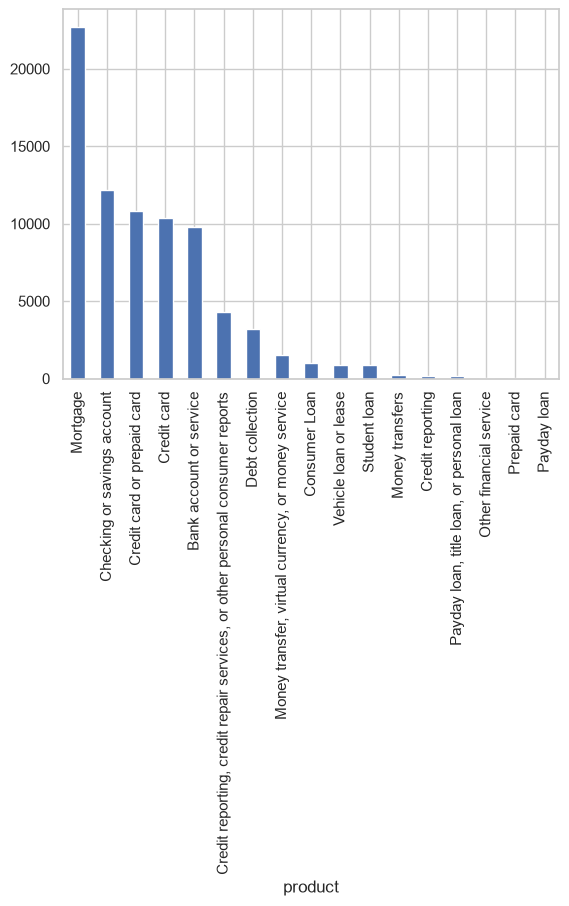

In [15]:
df['product'].value_counts().plot.bar()

Some products appear under two names, for example `Credit card` and `Credit card or prepaid card`, or `Bank account or service` and `Checking or savings account`.
I will merge these later.

In [16]:
df['company_response'].value_counts()

company_response
Closed with explanation            60230
Closed with monetary relief        10129
Closed with non-monetary relief     4383
Closed without relief               2009
Closed with relief                   813
Closed                               628
In progress                          119
Untimely response                      2
Name: count, dtype: int64

In [17]:
df['submitted_via'].value_counts()

submitted_via
Web            47972
Referral       19550
Phone           6220
Postal mail     3486
Fax             1060
Email             25
Name: count, dtype: int64

In [18]:
df['tags'].value_counts(dropna=False)

tags
NaN                              67413
Older American                    6103
Servicemember                     3759
Older American, Servicemember     1038
Name: count, dtype: int64

Now the text itself. I only look at the rows that have text.

In [19]:
# count number of chars in evey complain
text = df.loc[df.has_text, 'complaint_what_happened']
words = text.str.split().str.len()

# statistics of complain length
words.describe().round(0)

count    21072.0
mean       253.0
std        271.0
min          1.0
25%         97.0
50%        181.0
75%        319.0
max       5573.0
Name: complaint_what_happened, dtype: float64

<Axes: xlabel='complaint_what_happened', ylabel='Count'>

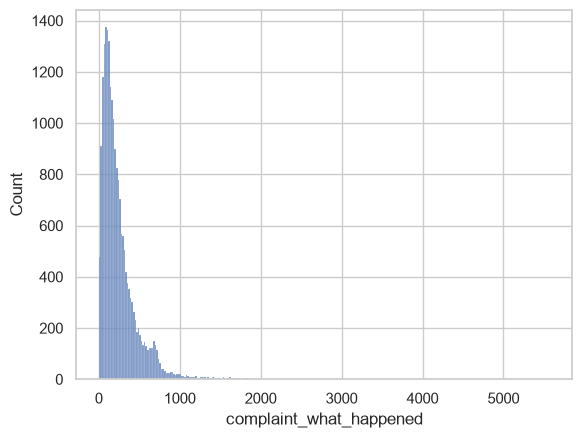

In [20]:
sns.histplot(text.str.split().str.len())

In [21]:
print('very short (<15 words):', (words < 15).sum())
print('contain XXXX:', round(text.str.contains('XXXX').mean() * 100), '%')
print('exact duplicate texts:', text.duplicated().sum())

very short (<15 words): 246
contain XXXX: 85 %
exact duplicate texts: 142


In [22]:
text[words < 15].head(5).tolist()

['Can you please remove inquiry',
 'mishandling of this account by Chase auto and XXXX.',
 'ChaseMortgagehasautomaticallydeducted2mortgagepaymentsfrommyXXXXXXXXcheckingaccountwithoutmypermission.Iamnotsetupuponautomaticpayments.IdidnotauthorizethemtodeductandIamcurrentonmyloan.',
 'On XX/XX/2019, JPMCB CARD add a hard inquiry on my credit report per XXXX.',
 'XXXX, XXXX, XXXX AND XXXX XXXX ILLEGALLY PULLED MY CREDIT.']

In [23]:
text.duplicated().sum()

np.int64(142)

In [24]:
# check duplicated complains
text[text.duplicated(keep=False)]

15                                                         Can you please remove inquiry
168      My personal information was used without my knowledge and because of several...
443      On XX/XX/XXXX I filed a dispute with Chase Bank for {$2000.00} on a {$4700.0...
665      I have paid the balance of the JPMCB Card with the negotiated understanding ...
834      I have always paid my account on time every month thru the website that the ...
                                              ...                                       
75915    Chase Bank has violated 15 USC 1692 by continuing collection activity after ...
76051    Chase has violated 15 USC 1692 by continuing collection activity after a cea...
76842    Chase has violated 15 USC 1692 by continuing collection activity after a cea...
76863    Chase has violated 15 USC 1692 by continuing collection activity after a cea...
77205    I noticed my credit card was not working so i called chase and they said the...
Name: complaint_what_

In [25]:
# DISPLAY RANDOM COMPLAINS

text.sample().tolist()

['My spouse and I both have Chase Auto Credit loans. My loan was financed about 4 1/2 years ago and my husband recently financed a XXXX XXXX XXXX. We also have two Chase credit cards. When the auto loan was funded, Chase immediately linked it to his other account. So, I went in to the account to schedule the first payment. It would n\'t allow me to schedule it because it stated a bank account had not been linked. So, I went into " add external accounts \'\' and added our checking account information. Then, I received an error message that stated an account with this information already exists in another profile. So, I messaged Chase about 48 hours ago to let them know we were experiencing a problem linking the checking account. I had the same problem 4 1/2 years ago when I purchased my XXXX, because our account information was linked to my credit card. As of today, I still had not heard from Chase. So I called them like I did 4 1/2 years ago to resolve the problem. The first rep I spok


## Quality issues
- company_public_response has no values
- consumer_consent_provided, tags, sub_issue and complaint_what_happened majority of data is missing
- Some products appear under two names, for example `Credit card` and `Credit card or prepaid card`, or `Bank account or service` and `Checking or savings account`.
- Only about 27% of the complaints have text, so the text analysis only covers that part.
- duplicated complains
- `company_public_response` is almost completely empty, and `consumer_disputed` and `consumer_consent_provided` are half empty.
- Some texts are very short or exact duplicates.
- The text has `XXXX` placeholders (names, dates and numbers hidden by the source).

- `date_received` is a string with a time and timezone attached.
- The same product has more than one name.
- `tags`, `sub_issue`, `sub_product` and `state` have missing values that really mean "none".
- Only one company, so `company` has no use.

## 3. Cleaning

I work on a copy so the raw dataframe stays untouched.

In [26]:
df_clean = df.copy()

**Drop columns I do not need.** `company`, `company_public_response` and `timely` carry no information here.
I also drop `consumer_disputed` and `consumer_consent_provided`: the first is only known after the case is closed, and the second only explains why text is missing.
`zip_code` and `date_sent_to_company` are not needed for this analysis.

In [27]:
drop_cols = ['company', 'company_public_response', 'timely', 'consumer_disputed',
             'consumer_consent_provided', 'zip_code', 'date_sent_to_company']
df_clean = df_clean.drop(columns=drop_cols)
df_clean.shape

(78313, 13)

**Dates.** I keep only the date part (the time is always noon and the timezone is just noise).

In [28]:
df_clean['date_received'] = pd.to_datetime(df_clean['date_received'])
df_clean['year'] = df_clean['date_received'].dt.year
df_clean['date_received'].dtype

datetime64[us, UTC-05:00]

**Product names.** Merge the old and new names into one column.

In [29]:
product_map = {
    'Credit card': 'Credit/prepaid card',
    'Credit card or prepaid card': 'Credit/prepaid card',
    'Prepaid card': 'Credit/prepaid card',
    'Bank account or service': 'Checking/savings',
    'Checking or savings account': 'Checking/savings',
    'Money transfers': 'Money transfer',
    'Money transfer, virtual currency, or money service': 'Money transfer',
    'Credit reporting, credit repair services, or other personal consumer reports': 'Credit reporting',
    'Credit reporting': 'Credit reporting',
    'Consumer Loan': 'Personal/consumer loan',
    'Payday loan': 'Personal/consumer loan',
    'Payday loan, title loan, or personal loan': 'Personal/consumer loan',
    'Other financial service': 'Other',
}
df_clean['product_group'] = df_clean['product'].replace(product_map)
df_clean['product_group'].value_counts()

product_group
Mortgage                  22725
Checking/savings          21963
Credit/prepaid card       21202
Credit reporting           4502
Debt collection            3201
Money transfer             1728
Personal/consumer loan     1174
Vehicle loan or lease       892
Student loan                866
Other                        60
Name: count, dtype: int64

In [30]:
# drop product column

df_clean.drop(columns=['product'], inplace=True)

**Missing values that mean "none".**

In [31]:
df_clean['tags'] = df_clean['tags'].fillna('none')
df_clean['sub_issue'] = df_clean['sub_issue'].fillna('none')
df_clean['sub_product'] = df_clean['sub_product'].fillna('none')
df_clean['state'] = df_clean['state'].fillna('unknown')
df_clean[['tags', 'sub_issue', 'sub_product', 'state']].isna().sum()

tags           0
sub_issue      0
sub_product    0
state          0
dtype: int64

In [32]:
df_clean.head(5)

,tags,complaint_id,issue,date_received,state,company_response,submitted_via,sub_product,complaint_what_happened,sub_issue,has_text,year,product_group
0,none,3211475,Attempts to collect debt not owed,2019-04-13 12:00:00-05:00,CA,Closed with explanation,Web,Credit card debt,NaN,Debt is not yours,False,2019,Debt collection
1,Servicemember,3229299,Written notification about debt,2019-05-01 12:00:00-05:00,GA,Closed with explanation,Web,Credit card debt,Good morning my name is XXXX XXXX and I appreciate it if you could help me p...,Didn't receive enough information to verify debt,True,2019,Debt collection
2,none,3199379,"Other features, terms, or problems",2019-04-02 12:00:00-05:00,TX,Closed with explanation,Web,General-purpose credit card or charge card,I upgraded my XXXX XXXX card in XX/XX/2018 and was told by the agent who did...,Problem with rewards from credit card,True,2019,Credit/prepaid card
3,none,2673060,Trouble during payment process,2017-09-13 12:00:00-05:00,MI,Closed with explanation,Web,Conventional home mortgage,NaN,none,False,2017,Mortgage
4,none,3203545,Fees or interest,2019-04-05 12:00:00-05:00,NY,Closed with explanation,Referral,General-purpose credit card or charge card,NaN,Charged too much interest,False,2019,Credit/prepaid card


**Keep only complaints with text.** The next notebook needs the narrative, so I filter here and note how many rows are left.

In [33]:
df_clean = df_clean[df_clean['has_text']].drop(columns='has_text')
len(df_clean)

21072

**Tidy the text.** I keep the original wording in `text` (only fixing whitespace) and add a `clean_text` column for modelling:
lowercase, no `XXXX` placeholders, no dollar amounts, no digits or punctuation.

In [34]:
# remove extra spaces and new lines
# rename the complain to be text
df_clean['text'] = df_clean['complaint_what_happened'].str.replace(r'\s+', ' ', regex=True).str.strip()
df_clean = df_clean.drop(columns='complaint_what_happened')
df_clean['text'].head(2).tolist()

['Good morning my name is XXXX XXXX and I appreciate it if you could help me put a stop to Chase Bank cardmember services. In 2018 I wrote to Chase asking for debt verification and what they sent me a statement which is not acceptable. I am asking the bank to validate the debt. Instead I been receiving mail every month from them attempting to collect a debt. I have a right to know this information as a consumer. Chase account # XXXX XXXX XXXX XXXX Thanks in advance for your help.',
 'I upgraded my XXXX XXXX card in XX/XX/2018 and was told by the agent who did the upgrade my anniversary date would not change. It turned the agent was giving me the wrong information in order to upgrade the account. XXXX changed my anniversary date from XX/XX/XXXX to XX/XX/XXXX without my consent! XXXX has the recording of the agent who was misled me.']

In [35]:
def clean_text(t):
    t = t.lower()
    t = re.sub(r'x{2,}(/x{2,})*(/\d{2,4})?', ' ', t)   # XXXX and XX/XX/2019 placeholders
    t = re.sub(r'\{\$?[\d\.,]+\}', ' ', t)             # {$100.00} amounts
    t = re.sub(r'[^a-z\s]', ' ', t)                      # digits and punctuation
    return re.sub(r'\s+', ' ', t).strip()

In [36]:
df_clean['clean_text'] = df_clean['text'].apply(clean_text)
df_clean['n_words'] = df_clean['clean_text'].str.split().str.len()
df_clean[['text', 'clean_text']].head(2)

,text,clean_text
1,Good morning my name is XXXX XXXX and I appreciate it if you could help me p...,good morning my name is and i appreciate it if you could help me put a stop ...
2,I upgraded my XXXX XXXX card in XX/XX/2018 and was told by the agent who did...,i upgraded my card in and was told by the agent who did the upgrade my anniv...


**Remove very short texts and duplicates.** Under 15 words there is not enough to tell what the complaint is about.
For duplicates I keep the earliest one.

In [37]:
before = len(df_clean)
df_clean = df_clean[df_clean['n_words'] >= 15]
print('removed short texts:', before - len(df_clean))

removed short texts: 298


In [38]:
before = len(df_clean)
df_clean = df_clean.sort_values('date_received').drop_duplicates('clean_text', keep='first')
print('removed duplicates:', before - len(df_clean))

removed duplicates: 223


In [39]:
df_clean = df_clean.reset_index(drop=True)
df_clean.shape

(20551, 14)

In [40]:
df_clean.head()

,tags,complaint_id,issue,date_received,state,company_response,submitted_via,sub_product,sub_issue,year,product_group,text,clean_text,n_words
0,Older American,1290253,"Loan servicing, payments, escrow account",2015-03-19 12:00:00-05:00,CA,Closed with explanation,Web,Conventional fixed mortgage,none,2015,Mortgage,I have an open and current mortgage with Chase Bank # XXXX. Chase is reporti...,i have an open and current mortgage with chase bank chase is reporting the l...,67
1,none,1291150,"Loan servicing, payments, escrow account",2015-03-19 12:00:00-05:00,NY,Closed with explanation,Web,Conventional fixed mortgage,none,2015,Mortgage,My mortgage lender is refusing to cancel private mortgage insurance from my ...,my mortgage lender is refusing to cancel private mortgage insurance from my ...,182
2,none,1292174,Identity theft / Fraud / Embezzlement,2015-03-19 12:00:00-05:00,NY,Closed with monetary relief,Web,none,none,2015,Credit/prepaid card,I am a credit card account holder with Chase. My card card account was compr...,i am a credit card account holder with chase my card card account was compro...,193
3,Older American,1291516,Billing statement,2015-03-19 12:00:00-05:00,FL,Closed with explanation,Web,none,none,2015,Credit/prepaid card,My credit report is showing a balance on a credit card that does not exist,my credit report is showing a balance on a credit card that does not exist,15
4,none,1291026,Advertising and marketing,2015-03-19 12:00:00-05:00,NE,Closed with explanation,Web,none,none,2015,Credit/prepaid card,When I signed up for my Chase Freedom Visa credit card on XXXX XXXX of XXXX ...,when i signed up for my chase freedom visa credit card on of there was a pro...,382


In [41]:
df_clean.isna().sum()

tags                0
complaint_id        0
issue               0
date_received       0
state               0
company_response    0
submitted_via       0
sub_product         0
sub_issue           0
year                0
product_group       0
text                0
clean_text          0
n_words             0
dtype: int64

**Quick checks** before moving on.

In [42]:
assert df_clean['complaint_id'].is_unique
assert df_clean['clean_text'].str.len().min() > 0
assert df_clean[['text', 'clean_text', 'product_group', 'date_received']].isna().sum().sum() == 0
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 20551 entries, 0 to 20550
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype                    
---  ------            --------------  -----                    
 0   tags              20551 non-null  str                      
 1   complaint_id      20551 non-null  int64                    
 2   issue             20551 non-null  str                      
 3   date_received     20551 non-null  datetime64[us, UTC-05:00]
 4   state             20551 non-null  str                      
 5   company_response  20551 non-null  str                      
 6   submitted_via     20551 non-null  str                      
 7   sub_product       20551 non-null  str                      
 8   sub_issue         20551 non-null  str                      
 9   year              20551 non-null  int32                    
 10  product_group     20551 non-null  str                      
 11  text              20551 non-null  str               

## 4. EDA

From here on I only use the clean data.

In [43]:
df_clean['date_received'].min(), df_clean['date_received'].max()

(Timestamp('2015-03-19 12:00:00-0500', tz='UTC-05:00'),
 Timestamp('2021-03-14 12:00:00-0500', tz='UTC-05:00'))

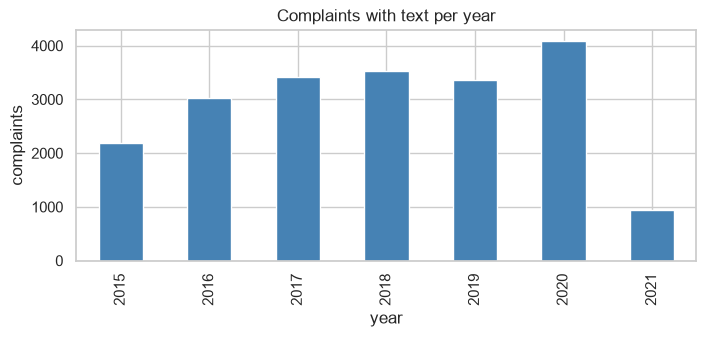

In [44]:
df_clean.groupby('year').size().plot(kind='bar', figsize=(8, 3), color='steelblue')
plt.title('Complaints with text per year')
plt.ylabel('complaints')
plt.show()

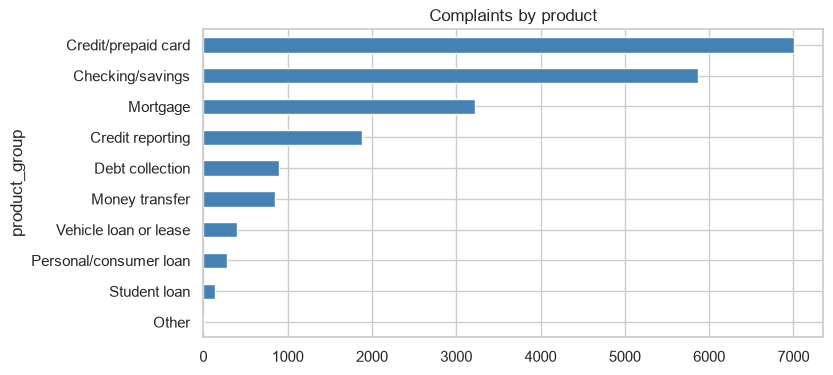

In [45]:
df_clean['product_group'].value_counts().sort_values().plot(kind='barh', figsize=(8, 4), color='steelblue')
plt.title('Complaints by product')
plt.show()

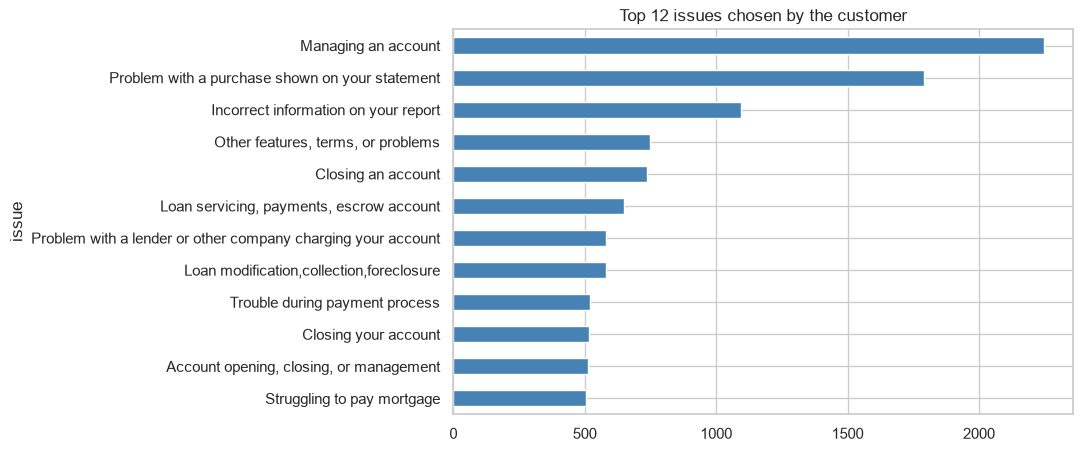

In [46]:
df_clean['issue'].value_counts().head(12).sort_values().plot(kind='barh', figsize=(8, 5), color='steelblue')
plt.title('Top 12 issues chosen by the customer')
plt.show()

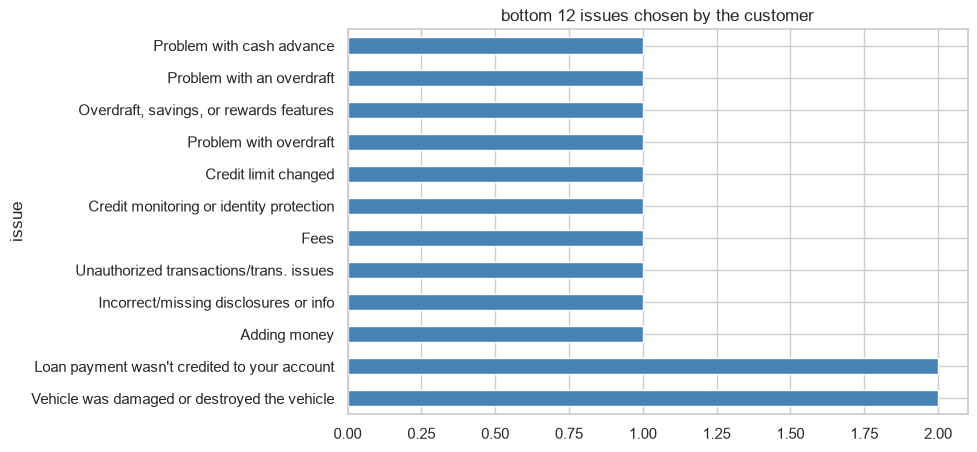

In [47]:
df_clean['issue'].value_counts().tail(12).sort_values(ascending=False).plot(kind='barh', figsize=(8, 5), color='steelblue')
plt.title('bottom 12 issues chosen by the customer')
plt.show()

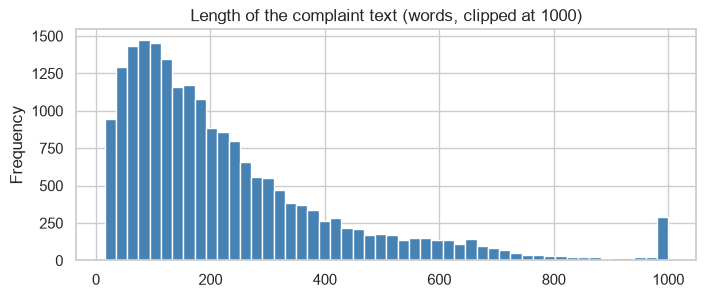

In [48]:
df_clean['n_words'].clip(upper=1000).plot(kind='hist', bins=50, figsize=(8, 3), color='steelblue')
plt.title('Length of the complaint text (words, clipped at 1000)')
plt.show()

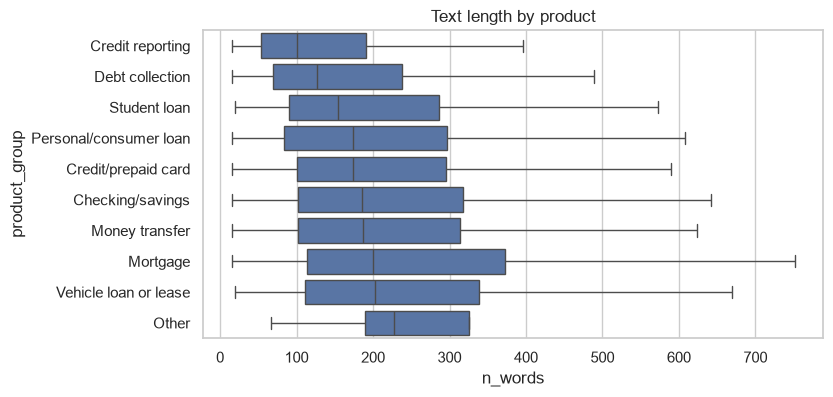

In [49]:
order = df_clean.groupby('product_group')['n_words'].median().sort_values().index
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_clean, y='product_group', x='n_words', order=order, showfliers=False)
plt.title('Text length by product')
plt.show()

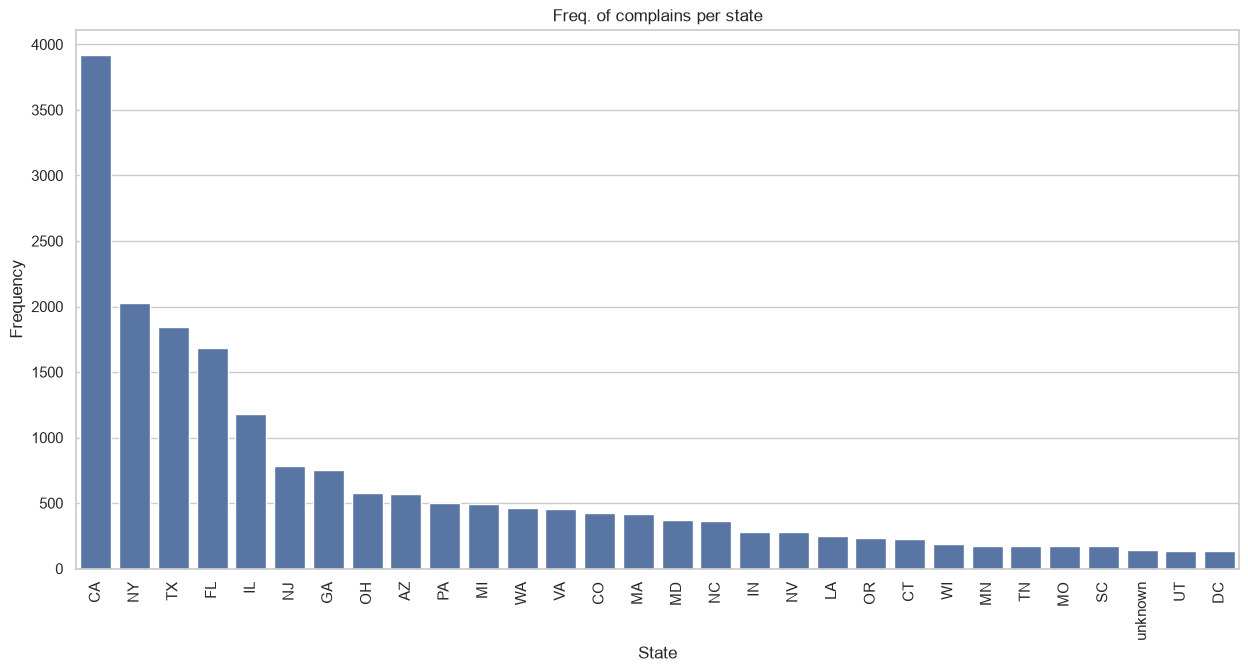

In [50]:
# count of complains per state
plt.figure(figsize=(15, 7))
sns.countplot(x=df_clean['state'], order=df_clean['state'].value_counts().index[:30])
plt.xticks(rotation=90);


plt.title("Freq. of complains per state")
plt.xlabel('State')
plt.ylabel("Frequency")
plt.show()

In [51]:
df_clean['submitted_via'].value_counts(normalize=True).round(3)

submitted_via
Web    1.0
Name: proportion, dtype: float64

In [52]:
df_clean['tags'].value_counts(normalize=True).round(3)

tags
none                             0.817
Older American                   0.089
Servicemember                    0.077
Older American, Servicemember    0.017
Name: proportion, dtype: float64

In [53]:
df_clean['company_response'].value_counts(normalize=True).round(3)

company_response
Closed with explanation            0.767
Closed with monetary relief        0.161
Closed with non-monetary relief    0.070
Closed                             0.002
Name: proportion, dtype: float64

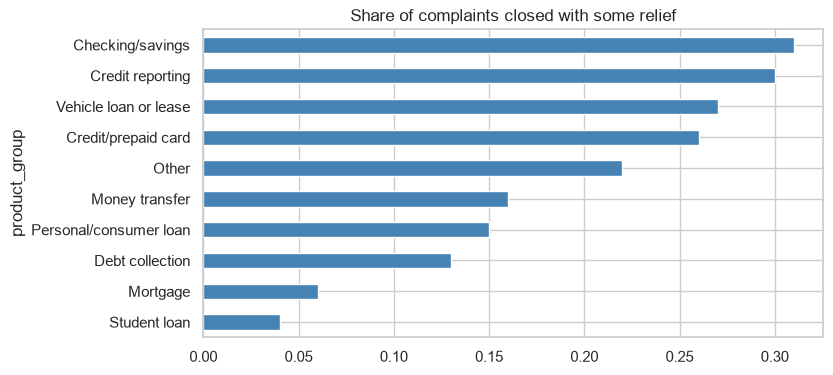

In [54]:
relief = ['Closed with monetary relief', 'Closed with non-monetary relief', 'Closed with relief']
df_clean['got_relief'] = df_clean['company_response'].isin(relief)
df_clean.groupby('product_group')['got_relief'].mean().sort_values().round(2).plot(kind='barh', figsize=(8, 4), color='steelblue')
plt.title('Share of complaints closed with some relief')
plt.show()

In [55]:
df_clean.groupby('year')['got_relief'].mean().round(2)

year
2015    0.13
2016    0.18
2017    0.25
2018    0.28
2019    0.26
2020    0.24
2021    0.20
Name: got_relief, dtype: float64

In [56]:
df_clean['state'].value_counts().head(10)

state
CA    3917
NY    2027
TX    1840
FL    1682
IL    1179
NJ     782
GA     751
OH     579
AZ     570
PA     502
Name: count, dtype: int64

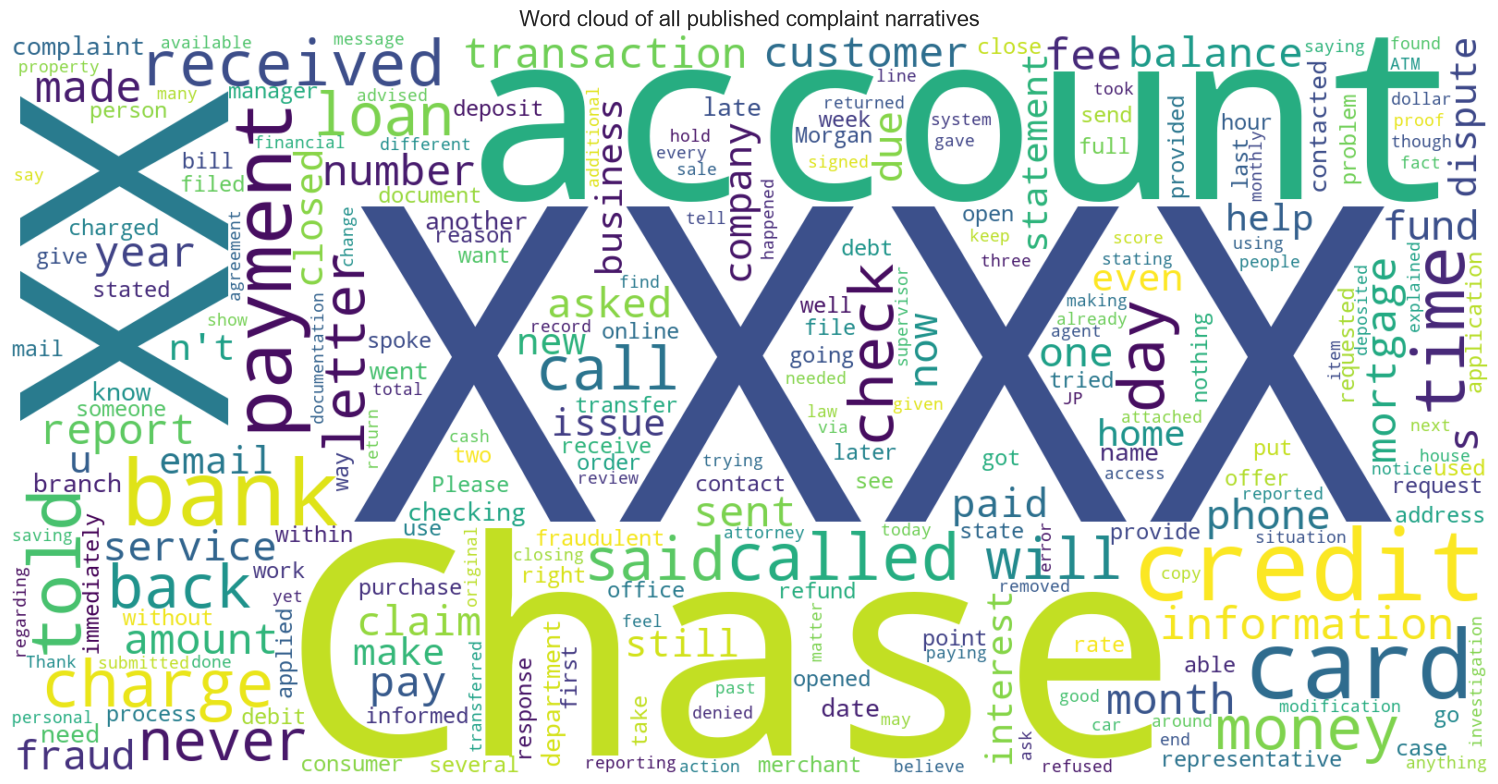

In [57]:
#the most frequent words once common stop-words are removed.

from wordcloud import WordCloud, STOPWORDS

all_text = " ".join(df_clean['text'])


wc = WordCloud(
    width=1600,
    height=800,
    background_color="white",
    stopwords=STOPWORDS,
    max_words=250,
    collocations=False,
).generate(all_text)

plt.figure(figsize=(16, 8))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word cloud of all published complaint narratives", fontsize=16)
plt.tight_layout()
plt.show()

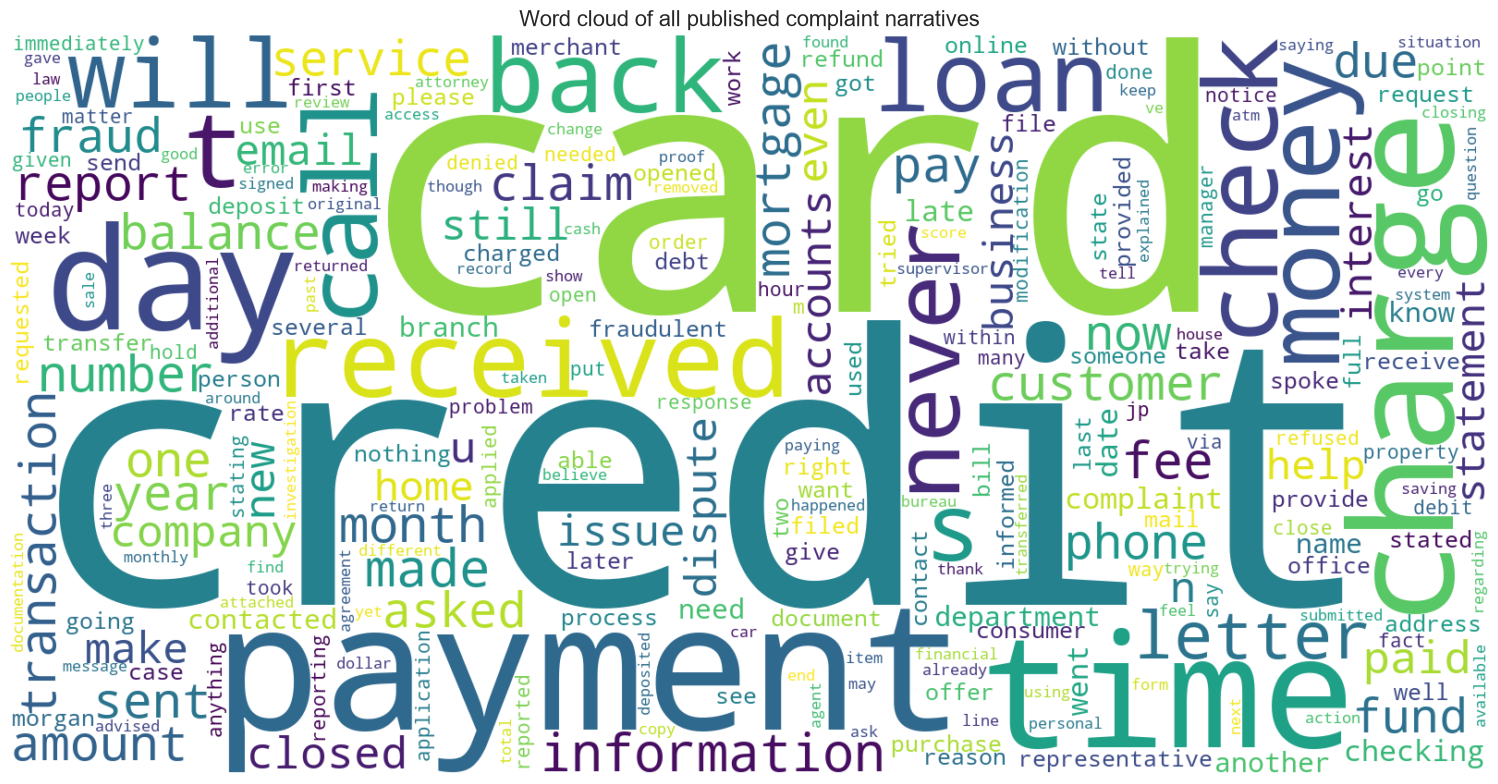

In [62]:
#the most frequent words once common stop-words are removed.

from wordcloud import WordCloud, STOPWORDS

all_text = " ".join(df_clean['clean_text'])


wc = WordCloud(
    width=1600,
    height=800,
    background_color="white",
    stopwords=STOPWORDS | {'chase', 'bank', 'account', 'would', 'could', 'called', 'told', 'said', 'also'},
    max_words=250,
    collocations=False,
).generate(all_text)

plt.figure(figsize=(16, 8))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word cloud of all published complaint narratives", fontsize=16)
plt.tight_layout()
plt.show()

In [58]:
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop = set(ENGLISH_STOP_WORDS) | {'chase', 'bank', 'account', 'would', 'could', 'called', 'told', 'said', 'also'}
counts = Counter(w for t in df_clean['clean_text'] for w in t.split() if w not in stop and len(w) > 2)
counts.most_common(20)

[('credit', 32304),
 ('card', 26712),
 ('did', 15888),
 ('payment', 14022),
 ('received', 12806),
 ('time', 12169),
 ('money', 11949),
 ('loan', 10036),
 ('check', 9762),
 ('information', 9588),
 ('letter', 8424),
 ('sent', 8315),
 ('pay', 7964),
 ('mortgage', 7956),
 ('number', 7757),
 ('days', 7506),
 ('phone', 7501),
 ('asked', 7438),
 ('payments', 7185),
 ('balance', 7176)]

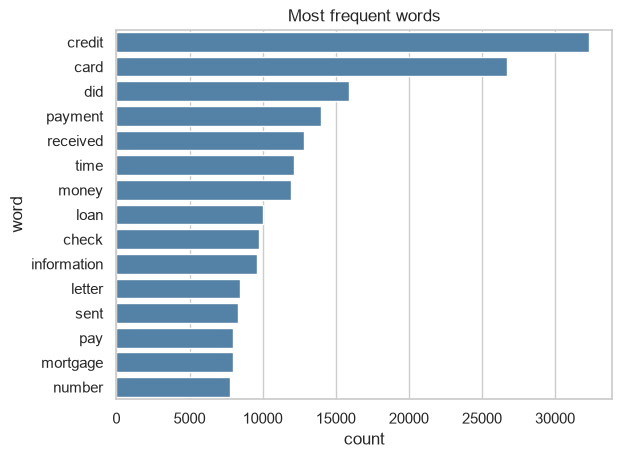

In [59]:
top = pd.DataFrame(counts.most_common(15), columns=['word', 'count'])
sns.barplot(data=top, y='word', x='count', color='steelblue')
plt.title('Most frequent words')
plt.show()

### What the EDA shows

- After cleaning I have **20,551 complaints** from March 2015 to March 2021 (2021 is only a partial year), roughly 3,000 to 4,000 a year.
- **Products:** credit/prepaid card (34%), checking/savings (29%) and mortgage (16%) make up about 80% of the complaints.
- **Customer-chosen issues are vague.** The most common one is "Managing an account" (11%), and "Other features, terms, or problems" is also in the top five. This is why I want to find topics from the text instead of relying on this field.
- **Length:** the median complaint is about 170 words, but the longest are much longer (the 95th percentile is about 650 words). Mortgage complaints are the longest, credit reporting and debt collection the shortest.
- **Channel:** every complaint with text came through the web, so `submitted_via` has no use as a feature on this data.
- **Tags:** about 18% of complaints are tagged Older American and/or Servicemember.
- **Outcome:** 77% are closed with an explanation only, and about 23% end with some relief. Relief depends a lot on the product (around 30% for checking/savings and credit reporting, about 6% for mortgage and 4% for student loans) and it went up over the years (13% in 2015, 26% in 2019).
- **Words:** the most frequent words (credit, card, payment, money, loan, check) already hint at the themes, but they are generic, so a topic model should do better.

**For the next notebook:** use `clean_text` for modelling and `text` when I want to read the original wording.

## 5. Save the clean data

I drop the helper column `got_relief` (it can be rebuilt from `company_response`) and save the file for the taxonomy notebook.

In [60]:
cols = ['complaint_id', 'date_received', 'year', 'state', 'product_group', 'sub_product',
        'issue', 'sub_issue', 'submitted_via', 'tags', 'company_response',
        'text', 'clean_text', 'n_words']
Path('../data/clean').mkdir(parents=True, exist_ok=True)
df_clean[cols].to_csv('../data/clean/complaints_clean.csv', index=False)